# Lab 07 - Transformer Architecture


In [1]:
import os
import re
import math
import time
import random
from collections import Counter

# Đảm bảo thư mục làm việc luôn là thư mục lab07
if os.path.basename(os.getcwd()) != "lab07" and os.path.exists("lab07"):
    os.chdir("lab07")
print(f"Thư mục làm việc hiện tại: {os.getcwd()}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Thiết lập hạt giống ngẫu nhiên đảm bảo tính tái lập (Reproducibility)
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

# Thiết lập thiết bị tính toán
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị: {device}")


Thư mục làm việc hiện tại: /media/trong-thanh/Data/University/Fourth Year/NLP/lab07


Đang sử dụng thiết bị: cpu


## Experiment 1 - Positional Encoding & Permutation (Mục 11 & 12)


=== EXPERIMENT 1 KẾT QUẢ ===
Không có PE - Cosine similarity giữa seq1 và seq2: 1.000000
Có PE       - Cosine similarity giữa seq1 và seq2: 0.998918

=== PERMUTATION EXPERIMENT (Mục 12) ===
Không PE: Euclidean Distance(S1, S2) = 1.271920e-16  (HOÀN TOÀN TRÙNG NHAU!)
Có PE:    Euclidean Distance(S1, S2) = 0.2164  (ĐÃ TÁCH BIỆT RÕ RÀNG!)


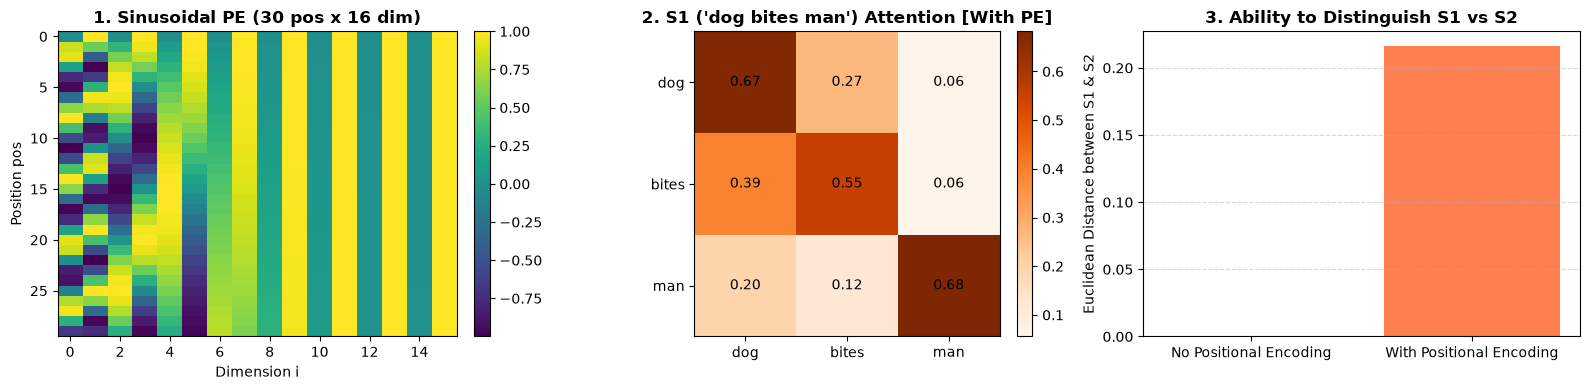

In [2]:
class SinusoidalPositionalEncoding(nn.Module):
    """Sinusoidal Positional Encoding (Vaswani et al., 2017)."""
    def __init__(self, d_model: int, max_len: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        pe = pe.unsqueeze(0)  # Shape: (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        seq_len = x.size(1)
        x = x + self.pe[:, :seq_len, :]
        return self.dropout(x)

def cosine_similarity(v1, v2):
    dot = np.dot(v1, v2)
    norm = np.linalg.norm(v1) * np.linalg.norm(v2)
    return dot / (norm + 1e-9)

def simple_self_attention(X):
    # X: (T, d)
    d_k = X.shape[-1]
    scores = (X @ X.T) / np.sqrt(d_k)
    exp_s = np.exp(scores - np.max(scores, axis=-1, keepdims=True))
    A = exp_s / np.sum(exp_s, axis=-1, keepdims=True)
    Z = A @ X
    return A, Z

# --- Experiment 1: ['I', 'love', 'NLP'] vs ['NLP', 'love', 'I'] ---
pe_calc = SinusoidalPositionalEncoding(d_model=4, max_len=10, dropout=0.0)
pe_mat = pe_calc.pe.squeeze(0).numpy()

vocab_toy = {
    "I": np.array([1.0, 0.0, 1.0, 0.0]),
    "love": np.array([0.0, 2.0, 0.0, 1.0]),
    "NLP": np.array([1.0, 1.0, 0.0, 1.0])
}
X1 = np.stack([vocab_toy["I"], vocab_toy["love"], vocab_toy["NLP"]])
X2 = np.stack([vocab_toy["NLP"], vocab_toy["love"], vocab_toy["I"]])

# Không có PE
_, Z1_no_pe = simple_self_attention(X1)
_, Z2_no_pe = simple_self_attention(X2)
mean_Z1_no = np.mean(Z1_no_pe, axis=0)
mean_Z2_no = np.mean(Z2_no_pe, axis=0)

# Có PE
PE3 = pe_mat[:3, :]
_, Z1_pe = simple_self_attention(X1 + PE3)
_, Z2_pe = simple_self_attention(X2 + PE3)
mean_Z1_pe = np.mean(Z1_pe, axis=0)
mean_Z2_pe = np.mean(Z2_pe, axis=0)

print("=== EXPERIMENT 1 KẾT QUẢ ===")
print(f"Không có PE - Cosine similarity giữa seq1 và seq2: {cosine_similarity(mean_Z1_no, mean_Z2_no):.6f}")
print(f"Có PE       - Cosine similarity giữa seq1 và seq2: {cosine_similarity(mean_Z1_pe, mean_Z2_pe):.6f}")

# --- Permutation Experiment: S1='dog bites man' vs S2='man bites dog' ---
vocab_perm = {
    "dog": np.array([1.2, 0.3, -0.5, 0.8]),
    "bites": np.array([0.1, 1.5, 0.2, -0.4]),
    "man": np.array([-0.8, 0.2, 1.4, 0.5]),
}
S1_X = np.stack([vocab_perm["dog"], vocab_perm["bites"], vocab_perm["man"]])
S2_X = np.stack([vocab_perm["man"], vocab_perm["bites"], vocab_perm["dog"]])

A1_no, Z1_p_no = simple_self_attention(S1_X)
A2_no, Z2_p_no = simple_self_attention(S2_X)
rep1_no = np.mean(Z1_p_no, axis=0)
rep2_no = np.mean(Z2_p_no, axis=0)

A1_p, Z1_p_pe = simple_self_attention(S1_X + PE3)
A2_p, Z2_p_pe = simple_self_attention(S2_X + PE3)
rep1_pe = np.mean(Z1_p_pe, axis=0)
rep2_pe = np.mean(Z2_p_pe, axis=0)

dist_no_pe = np.linalg.norm(rep1_no - rep2_no)
dist_with_pe = np.linalg.norm(rep1_pe - rep2_pe)

print("\n=== PERMUTATION EXPERIMENT (Mục 12) ===")
print(f"Không PE: Euclidean Distance(S1, S2) = {dist_no_pe:.6e}  (HOÀN TOÀN TRÙNG NHAU!)")
print(f"Có PE:    Euclidean Distance(S1, S2) = {dist_with_pe:.4f}  (ĐÃ TÁCH BIỆT RÕ RÀNG!)")

# Trực quan hóa và lưu positional_encoding.png
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Heatmap PE lớn
pe_large = SinusoidalPositionalEncoding(d_model=16, max_len=30, dropout=0.0).pe.squeeze(0).numpy()
im0 = axes[0].imshow(pe_large, cmap="viridis", aspect="auto")
axes[0].set_title("1. Sinusoidal PE (30 pos x 16 dim)", fontweight="bold")
axes[0].set_xlabel("Dimension i")
axes[0].set_ylabel("Position pos")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# 2. Attention S1 có PE
im1 = axes[1].imshow(A1_p, cmap="Oranges")
axes[1].set_xticks(range(3)); axes[1].set_yticks(range(3))
axes[1].set_xticklabels(["dog", "bites", "man"]); axes[1].set_yticklabels(["dog", "bites", "man"])
axes[1].set_title("2. S1 ('dog bites man') Attention [With PE]", fontweight="bold")
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, f"{A1_p[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# 3. Bar chart khoảng cách phân biệt
axes[2].bar(["No Positional Encoding", "With Positional Encoding"], [dist_no_pe, dist_with_pe], color=["steelblue", "coral"])
axes[2].set_ylabel("Euclidean Distance between S1 & S2")
axes[2].set_title("3. Ability to Distinguish S1 vs S2", fontweight="bold")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("positional_encoding.png", dpi=300)
plt.show()


## Core Implementation - Transformer Block (Mục 17 & 18)


In [3]:
class MultiHeadAttention(nn.Module):
    """Multi-Head Attention tự ghép từ Linear layers và Scaled Dot-Product."""
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % n_heads == 0, f"d_model ({d_model}) phải chia hết cho n_heads ({n_heads})"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        self.w_q = nn.Linear(d_model, d_model, bias=False)
        self.w_k = nn.Linear(d_model, d_model, bias=False)
        self.w_v = nn.Linear(d_model, d_model, bias=False)
        self.w_o = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, mask: torch.Tensor = None):
        B, T, _ = q.size()
        # Chiếu và phân chia heads: (B, T, d_model) -> (B, n_heads, T, d_k)
        Q = self.w_q(q).view(B, -1, self.n_heads, self.d_k).transpose(1, 2)
        K = self.w_k(k).view(B, -1, self.n_heads, self.d_k).transpose(1, 2)
        V = self.w_v(v).view(B, -1, self.n_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product scores: (B, n_heads, T, T)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        attn_weights = F.softmax(scores, dim=-1)
        attn_weights_drop = self.dropout(attn_weights)

        # Context vector: (B, n_heads, T, d_k)
        context = torch.matmul(attn_weights_drop, V)

        # Concat các heads lại: (B, T, d_model)
        concat = context.transpose(1, 2).contiguous().view(B, -1, self.d_model)
        output = self.w_o(concat)
        return output, attn_weights

class PositionwiseFeedForward(nn.Module):
    """FFN(x) = max(0, x W1 + b1) W2 + b2."""
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

class TransformerBlock(nn.Module):
    """Transformer Encoder Block hoàn chỉnh (Mục 17)."""
    def __init__(self, d_model: int, n_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.ffn = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None):
        attn_out, attn_weights = self.mha(x, x, x, mask=mask)
        x = self.norm1(x + self.dropout1(attn_out))
        ffn_out = self.ffn(x)
        out = self.norm2(x + self.dropout2(ffn_out))
        return out, attn_weights


In [4]:
# Kiểm tra Shape theo yêu cầu bắt buộc của Mục 18:
# B = 8 (batch_size), T = 100 (seq_len), d_model = 128, n_heads = 4 -> d_k = 32
B_test, T_test, d_model_test, n_heads_test, d_ff_test = 8, 100, 128, 4, 256
dummy_x = torch.randn(B_test, T_test, d_model_test)

test_block = TransformerBlock(d_model_test, n_heads_test, d_ff_test)
out_test, attn_test = test_block(dummy_x)

print("=== KIỂM TRA TENSOR SHAPES (Mục 18) ===")
print(f"X shape:               {dummy_x.shape}")
print(f"d_k = d_model / heads: {d_model_test // n_heads_test}")
print(f"Attention scores/attn: {attn_test.shape}   (Kỳ vọng: [8, 4, 100, 100])")
print(f"Transformer output:    {out_test.shape}    (Kỳ vọng: [8, 100, 128])")

assert attn_test.shape == (8, 4, 100, 100), "Lỗi shape ma trận attention!"
assert out_test.shape == (8, 100, 128), "Lỗi shape đầu ra của TransformerBlock!"
print("=> Tất cả kiểm tra shape ĐẠT chuẩn 100%!")


=== KIỂM TRA TENSOR SHAPES (Mục 18) ===
X shape:               torch.Size([8, 100, 128])
d_k = d_model / heads: 32
Attention scores/attn: torch.Size([8, 4, 100, 100])   (Kỳ vọng: [8, 4, 100, 100])
Transformer output:    torch.Size([8, 100, 128])    (Kỳ vọng: [8, 100, 128])
=> Tất cả kiểm tra shape ĐẠT chuẩn 100%!


## Chuẩn bị dữ liệu IMDb


In [5]:
def get_split_dir():
    candidates = ["datasets/splits", "lab07/datasets/splits", "../lab04/datasets/splits"]
    for path in candidates:
        if os.path.exists(os.path.join(path, "train.csv")):
            return path
    raise FileNotFoundError("Không tìm thấy thư mục splits chứa dữ liệu IMDb!")

split_dir = get_split_dir()
print(f"Thư mục dữ liệu: {split_dir}")

df_train = pd.read_csv(os.path.join(split_dir, "train.csv"))
df_val = pd.read_csv(os.path.join(split_dir, "val.csv"))
df_test = pd.read_csv(os.path.join(split_dir, "test.csv"))
print(f"Số lượng mẫu: Train = {len(df_train):,}, Val = {len(df_val):,}, Test = {len(df_test):,}")

# Tokenizer chuẩn
def clean_and_tokenize(text):
    text = re.sub(r"<[^>]+>", " ", str(text).lower())
    return re.findall(r"\b\w+\b", text)

# Xây dựng từ điển 20000 từ
counter = Counter()
for text in df_train["text"]:
    counter.update(clean_and_tokenize(text))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in counter.most_common(20000):
    vocab[word] = len(vocab)
inv_vocab = {idx: word for word, idx in vocab.items()}
print(f"Kích thước từ vựng (Vocabulary size): {len(vocab)}")

def encode_text(text, max_len=128):
    tokens = [vocab.get(w, 1) for w in clean_and_tokenize(text)][:max_len]
    return tokens + [0] * (max_len - len(tokens))

# Sử dụng tập huấn luyện chuẩn 10,000 mẫu để tối ưu thời gian huấn luyện trên CPU
max_seq_len = 128
batch_size = 128

train_sub_n = 10000
val_sub_n = 2500
test_sub_n = 2500

X_train_t = torch.tensor([encode_text(t, max_seq_len) for t in df_train["text"][:train_sub_n]], dtype=torch.long)
y_train_t = torch.tensor((df_train["label"][:train_sub_n] == "pos").values, dtype=torch.float32)

X_val_t = torch.tensor([encode_text(t, max_seq_len) for t in df_val["text"][:val_sub_n]], dtype=torch.long)
y_val_t = torch.tensor((df_val["label"][:val_sub_n] == "pos").values, dtype=torch.float32)

X_test_t = torch.tensor([encode_text(t, max_seq_len) for t in df_test["text"][:test_sub_n]], dtype=torch.long)
y_test_t = torch.tensor((df_test["label"][:test_sub_n] == "pos").values, dtype=torch.float32)
y_test_np = y_test_t.numpy()

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

print(f"Đã tạo DataLoader: Train ({len(train_loader)} batches), Val ({len(val_loader)} batches), Test ({len(test_loader)} batches)")


Thư mục dữ liệu: datasets/splits


Số lượng mẫu: Train = 34,707, Val = 7,437, Test = 7,438


Kích thước từ vựng (Vocabulary size): 20002


Đã tạo DataLoader: Train (79 batches), Val (20 batches), Test (20 batches)


## Định nghĩa Mô hình (TransformerClassifier & LSTMClassifier)


In [6]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, d_ff=256, num_classes=1,
                 pooling="mean", dropout=0.1, max_len=256, pad_idx=0):
        super().__init__()
        self.d_model = d_model
        self.pooling = pooling
        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_encoder = SinusoidalPositionalEncoding(d_model, max_len=max_len, dropout=dropout)
        self.transformer_block = TransformerBlock(d_model=d_model, n_heads=n_heads, d_ff=d_ff, dropout=dropout)
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, input_ids: torch.Tensor, return_attn: bool = False):
        mask = (input_ids != self.pad_idx).unsqueeze(1).unsqueeze(2)  # (B, 1, 1, T)
        x = self.embedding(input_ids) * math.sqrt(self.d_model)
        x = self.pos_encoder(x)
        x, attn_weights = self.transformer_block(x, mask=mask)

        if self.pooling == "mean":
            mask_float = (input_ids != self.pad_idx).unsqueeze(-1).float()
            pooled = torch.sum(x * mask_float, dim=1) / torch.clamp(mask_float.sum(dim=1), min=1e-9)
        elif self.pooling in ("cls", "first"):
            pooled = x[:, 0, :]
        else:
            raise ValueError(f"Unknown pooling: {self.pooling}")

        logits = self.classifier(pooled).squeeze(-1)
        if return_attn:
            return logits, attn_weights
        return logits

class LSTMClassifier(nn.Module):
    """Baseline LSTM từ LAB 05 để so sánh trực tiếp."""
    def __init__(self, vocab_size, d_model=128, hidden_dim=128, num_classes=1, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.lstm = nn.LSTM(d_model, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):
        emb = self.embedding(input_ids)
        _, (h_n, _) = self.lstm(emb)
        logits = self.fc(h_n[-1]).squeeze(-1)
        return logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_model(model, train_loader, val_loader, num_epochs=3, lr=1e-3, device=device):
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = []
    best_val_loss = float("inf")
    best_state = None

    t0 = time.time()
    for epoch in range(1, num_epochs + 1):
        model.train()
        total_train_loss = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * len(by)
        train_loss = total_train_loss / len(train_loader.dataset)

        # Validation
        model.eval()
        total_val_loss = 0.0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                logits = model(bx)
                loss = criterion(logits, by)
                total_val_loss += loss.item() * len(by)
                probs = torch.sigmoid(logits).cpu().numpy()
                val_preds.extend((probs >= 0.5).astype(int))
                val_targets.extend(by.cpu().numpy())
        val_loss = total_val_loss / len(val_loader.dataset)
        val_acc = accuracy_score(val_targets, val_preds)

        history.append((train_loss, val_loss, val_acc))
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:02d}/{num_epochs:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    total_time = time.time() - t0
    if best_state is not None:
        model.load_state_dict(best_state)
    return history, total_time

def evaluate_model(model, test_loader, device=device):
    model.eval()
    model.to(device)
    all_probs = []
    with torch.no_grad():
        for bx, _ in test_loader:
            bx = bx.to(device)
            logits = model(bx)
            probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.extend(probs)
    all_probs = np.array(all_probs)
    preds = (all_probs >= 0.5).astype(int)
    
    acc = accuracy_score(y_test_np, preds)
    prec = precision_score(y_test_np, preds, zero_division=0)
    rec = recall_score(y_test_np, preds, zero_division=0)
    f1 = f1_score(y_test_np, preds, zero_division=0)
    return acc, prec, rec, f1, all_probs


## Experiment 4 - Transformer vs LSTM (Mục 21)


In [7]:
print(">>> Huấn luyện Baseline: LSTM Classifier...")
lstm_model = LSTMClassifier(vocab_size=len(vocab), d_model=128, hidden_dim=128)
lstm_history, lstm_time = train_model(lstm_model, train_loader, val_loader, num_epochs=3, lr=1e-3)
lstm_acc, lstm_prec, lstm_rec, lstm_f1, lstm_probs = evaluate_model(lstm_model, test_loader)
lstm_params = count_parameters(lstm_model)

print("\n>>> Huấn luyện Mô hình chính: Transformer Encoder Classifier (4 Heads)...")
transformer_model = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=4, d_ff=256, pooling="mean")
trans_history, trans_time = train_model(transformer_model, train_loader, val_loader, num_epochs=3, lr=1e-3)
trans_acc, trans_prec, trans_rec, trans_f1, trans_probs = evaluate_model(transformer_model, test_loader)
trans_params = count_parameters(transformer_model)

df_exp4 = pd.DataFrame([
    {
        "Model": "LSTM (Baseline)",
        "Parameters": f"{lstm_params:,}",
        "Training time (s)": round(lstm_time, 2),
        "Accuracy": round(lstm_acc, 4),
        "Precision": round(lstm_prec, 4),
        "Recall": round(lstm_rec, 4),
        "F1": round(lstm_f1, 4)
    },
    {
        "Model": "Transformer (4 Heads)",
        "Parameters": f"{trans_params:,}",
        "Training time (s)": round(trans_time, 2),
        "Accuracy": round(trans_acc, 4),
        "Precision": round(trans_prec, 4),
        "Recall": round(trans_rec, 4),
        "F1": round(trans_f1, 4)
    }
])
display(df_exp4)


>>> Huấn luyện Baseline: LSTM Classifier...


Epoch 01/03 | Train Loss: 0.6922 | Val Loss: 0.6902 | Val Acc: 0.5356


Epoch 02/03 | Train Loss: 0.6661 | Val Loss: 0.6749 | Val Acc: 0.5940


Epoch 03/03 | Train Loss: 0.6181 | Val Loss: 0.6532 | Val Acc: 0.6108



>>> Huấn luyện Mô hình chính: Transformer Encoder Classifier (4 Heads)...


Epoch 01/03 | Train Loss: 0.6333 | Val Loss: 0.5526 | Val Acc: 0.7096


Epoch 02/03 | Train Loss: 0.5238 | Val Loss: 0.5332 | Val Acc: 0.7276


Epoch 03/03 | Train Loss: 0.4833 | Val Loss: 0.5166 | Val Acc: 0.7468


,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM (Baseline),"2,692,481",30.01,0.6124,0.6325,0.5218,0.5718
1,Transformer (4 Heads),"2,692,353",121.64,0.7444,0.7795,0.6758,0.7240


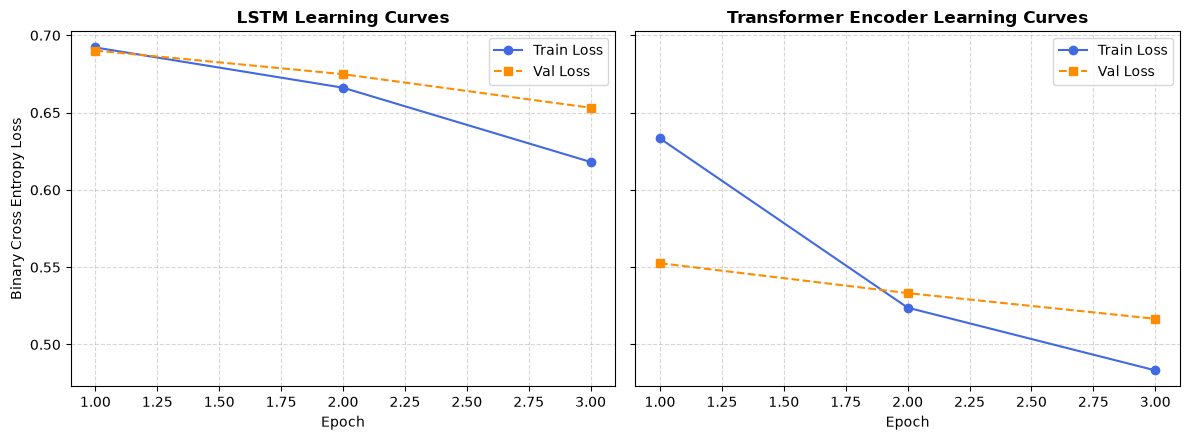

Đã lưu biểu đồ: learning_curves.png


In [8]:
# Vẽ và lưu learning_curves.png (Mục 29 & 32)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

models_hist = [("LSTM", lstm_history), ("Transformer Encoder", trans_history)]
for ax, (m_name, hist) in zip(axes, models_hist):
    epochs_range = range(1, len(hist) + 1)
    ax.plot(epochs_range, [h[0] for h in hist], marker="o", label="Train Loss", color="royalblue")
    ax.plot(epochs_range, [h[1] for h in hist], marker="s", linestyle="--", label="Val Loss", color="darkorange")
    ax.set_title(f"{m_name} Learning Curves", fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

axes[0].set_ylabel("Binary Cross Entropy Loss")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
plt.show()
print("Đã lưu biểu đồ: learning_curves.png")


## Experiment 2 - Số lượng Attention Heads (Mục 19)


In [9]:
head_configs = [1, 2, 4, 8]
head_results = []

for h in head_configs:
    d_k = 128 // h
    print(f"\n--- Đang thử nghiệm n_heads = {h} (d_k = {d_k}) ---")
    model_h = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=h, d_ff=256)
    _, h_time = train_model(model_h, train_loader, val_loader, num_epochs=2, lr=1e-3)
    h_acc, _, _, h_f1, _ = evaluate_model(model_h, test_loader)
    
    head_results.append({
        "Heads": h,
        "d_k": d_k,
        "Parameters": f"{count_parameters(model_h):,}",
        "Training time (s)": round(h_time, 2),
        "Accuracy": round(h_acc, 4),
        "F1": round(h_f1, 4)
    })

df_heads = pd.DataFrame(head_results)
print("\n=== BẢNG KẾT QUẢ EXPERIMENT 2 (Mục 19) ===")
display(df_heads)



--- Đang thử nghiệm n_heads = 1 (d_k = 128) ---


Epoch 01/02 | Train Loss: 0.6576 | Val Loss: 0.6024 | Val Acc: 0.6776


Epoch 02/02 | Train Loss: 0.5797 | Val Loss: 0.5601 | Val Acc: 0.7096



--- Đang thử nghiệm n_heads = 2 (d_k = 64) ---


Epoch 01/02 | Train Loss: 0.6396 | Val Loss: 0.5730 | Val Acc: 0.7036


Epoch 02/02 | Train Loss: 0.5475 | Val Loss: 0.5457 | Val Acc: 0.7184


... (4 outputs left out)

Epoch 01/02 | Train Loss: 0.6189 | Val Loss: 0.5427 | Val Acc: 0.7196


Epoch 02/02 | Train Loss: 0.4945 | Val Loss: 0.5132 | Val Acc: 0.7488



=== BẢNG KẾT QUẢ EXPERIMENT 2 (Mục 19) ===


,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,1,128,"2,692,353",50.42,0.6964,0.6713
1,2,64,"2,692,353",57.62,0.7220,0.6972
2,4,32,"2,692,353",72.76,0.7420,0.7385
3,8,16,"2,692,353",111.14,0.7640,0.7455


## Experiment 3 - Attention Head Diversity (Mục 20)


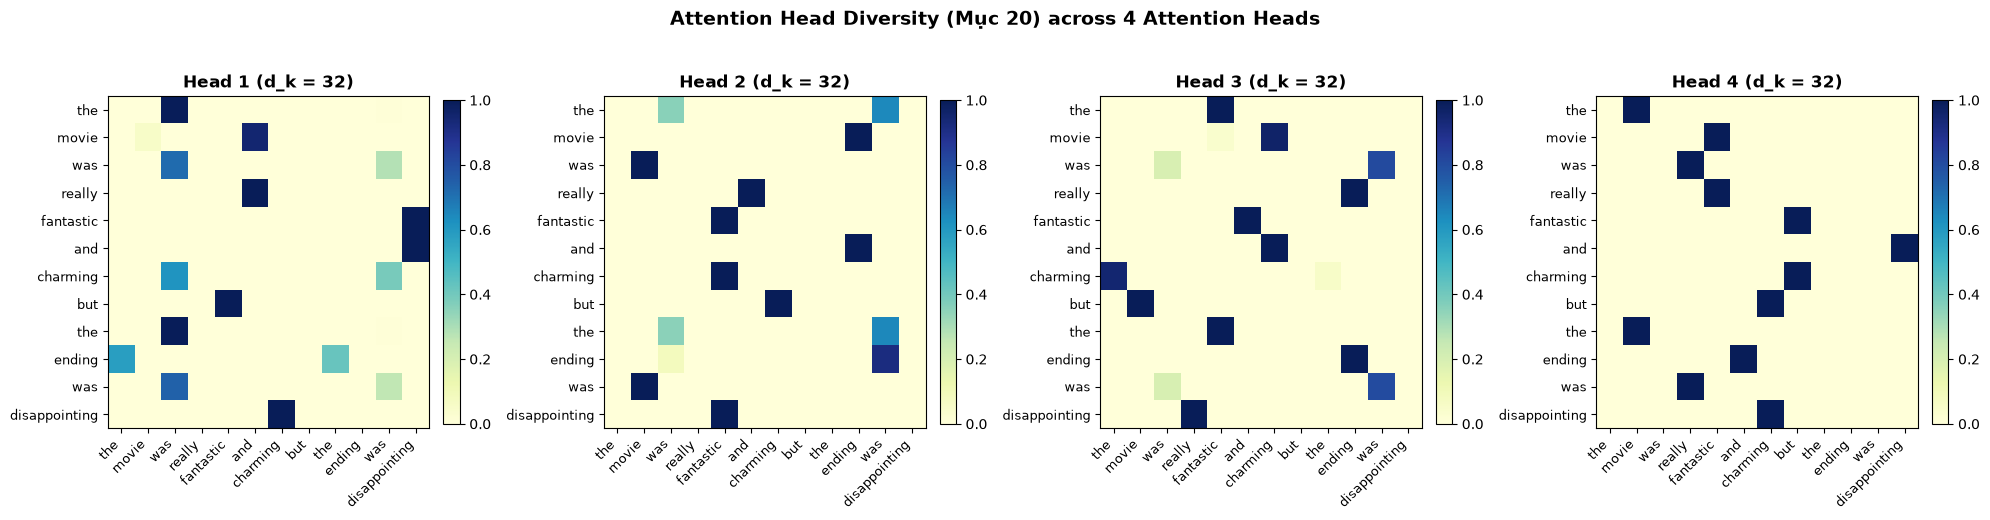

Đã lưu biểu đồ: attention_heads.png


In [10]:
sample_text = "the movie was really fantastic and charming but the ending was disappointing"
sample_tokens = clean_and_tokenize(sample_text)
sample_ids = torch.tensor([[vocab.get(w, 1) for w in sample_tokens]], dtype=torch.long).to(device)

transformer_model.eval()
with torch.no_grad():
    _, attn_weights = transformer_model(sample_ids, return_attn=True)

# attn_weights shape: (1, n_heads, T, T)
attn_np = attn_weights.squeeze(0).cpu().numpy()  # (4, T, T)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
T_tokens = len(sample_tokens)

for h in range(4):
    ax = axes[h]
    mat = attn_np[h, :T_tokens, :T_tokens]
    im = ax.imshow(mat, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(T_tokens))
    ax.set_yticks(range(T_tokens))
    ax.set_xticklabels(sample_tokens, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(sample_tokens, fontsize=9)
    ax.set_title(f"Head {h+1} (d_k = 32)", fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Attention Head Diversity (Mục 20) across 4 Attention Heads", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("attention_heads.png", dpi=300, bbox_inches="tight")
plt.show()
print("Đã lưu biểu đồ: attention_heads.png")


## Experiment 5 - Sequence Length & Chi phí O(T^2) (Mục 22)


In [11]:
seq_lengths = [32, 64, 128, 256]
seq_results = []

for L in seq_lengths:
    # Đo thời gian forward-backward trên 5 batches kích thước batch 64
    x_dummy = torch.randint(0, len(vocab), (64, L)).to(device)
    y_dummy = torch.randint(0, 2, (64,)).float().to(device)
    
    bench_model = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=4, d_ff=256, max_len=L).to(device)
    crit = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(bench_model.parameters(), lr=1e-3)

    t_start = time.time()
    for _ in range(5):
        opt.zero_grad()
        loss = crit(bench_model(x_dummy), y_dummy)
        loss.backward()
        opt.step()
    step_time = (time.time() - t_start) / 5

    seq_results.append({
        "Sequence Length T": L,
        "Attention Matrix Elements (T^2)": f"{L**2:,}",
        "Relative Memory Growth": f"{(L/32)**2:.1f}x",
        "Step Time (s/batch)": round(step_time, 4)
    })

df_seq = pd.DataFrame(seq_results)
print("=== BẢNG KHẢO SÁT SEQUENCE LENGTH & CHI PHÍ BẬC HAI (Mục 22) ===")
display(df_seq)


=== BẢNG KHẢO SÁT SEQUENCE LENGTH & CHI PHÍ BẬC HAI (Mục 22) ===


,Sequence Length T,Attention Matrix Elements (T^2),Relative Memory Growth,Step Time (s/batch)
0,32,"1,024",1.0x,0.0487
1,64,"4,096",4.0x,0.0983
2,128,"16,384",16.0x,0.2637
3,256,"65,536",64.0x,0.7493


## Experiment 6 - Pooling Strategy (Mục 24 & 25)


In [12]:
pooling_results = []

# Mean Pooling (đã huấn luyện ở trans_history)
pooling_results.append({
    "Pooling Strategy": "Masked Mean Pooling",
    "Accuracy": round(trans_acc, 4),
    "F1": round(trans_f1, 4),
    "Training time (s)": round(trans_time, 2)
})

# First-token pooling
print("--- Huấn luyện Transformer với First-token Pooling ---")
model_cls = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=4, d_ff=256, pooling="first")
_, cls_time = train_model(model_cls, train_loader, val_loader, num_epochs=2, lr=1e-3)
cls_acc, _, _, cls_f1, _ = evaluate_model(model_cls, test_loader)

pooling_results.append({
    "Pooling Strategy": "First-Token (CLS-style)",
    "Accuracy": round(cls_acc, 4),
    "F1": round(cls_f1, 4),
    "Training time (s)": round(cls_time, 2)
})

df_pooling = pd.DataFrame(pooling_results)
print("\n=== BẢNG SO SÁNH POOLING STRATEGY (Mục 25) ===")
display(df_pooling)


--- Huấn luyện Transformer với First-token Pooling ---


Epoch 01/02 | Train Loss: 0.7070 | Val Loss: 0.6921 | Val Acc: 0.5476


Epoch 02/02 | Train Loss: 0.6880 | Val Loss: 0.6884 | Val Acc: 0.5412



=== BẢNG SO SÁNH POOLING STRATEGY (Mục 25) ===


,Pooling Strategy,Accuracy,F1,Training time (s)
0,Masked Mean Pooling,0.7444,0.7240,121.64
1,First-Token (CLS-style),0.5304,0.5725,87.37


## Application - Kiểm thử các ca biên (Mục 23)


In [13]:
test_sentences = [
    ("Câu ngắn", "Loved it! Absolutely brilliant."),
    ("Câu dài", "I spent two hours watching this movie and while some visual scenes were pleasant, the overall storyline lacked coherence and character depth."),
    ("Phủ định (Negation)", "The film is not good at all, completely devoid of any humor or charm."),
    ("Tương phản (Contrast)", "The cinematography and acting were outstanding, but the plot was a complete disaster and boring."),
    ("Mơ hồ (Ambiguous)", "An unusual artistic experiment with bizarre pacing and eccentric characters that will divide audiences.")
]

def predict_sentence(text, model=transformer_model):
    model.eval()
    encoded = encode_text(text, max_seq_len)
    tensor_in = torch.tensor([encoded], dtype=torch.long).to(device)
    with torch.no_grad():
        logits = model(tensor_in)
        prob = torch.sigmoid(logits).item()
    pred_label = "Positive" if prob >= 0.5 else "Negative"
    return pred_label, prob

app_rows = []
for category, sent in test_sentences:
    pred, p = predict_sentence(sent)
    app_rows.append({
        "Category": category,
        "Input Sentence": sent,
        "Predicted Sentiment": pred,
        "Probability (Positive)": round(p, 4)
    })

df_app = pd.DataFrame(app_rows)
print("=== KẾT QUẢ THỬ NGHIỆM APPLICATION (Mục 23) ===")
display(df_app)


=== KẾT QUẢ THỬ NGHIỆM APPLICATION (Mục 23) ===


,Category,Input Sentence,Predicted Sentiment,Probability (Positive)
0,Câu ngắn,Loved it! Absolutely brilliant.,Positive,0.9986
1,Câu dài,I spent two hours watching this movie and whil...,Negative,0.3074
2,Phủ định (Negation),"The film is not good at all, completely devoid...",Positive,0.5902
3,Tương phản (Contrast),The cinematography and acting were outstanding...,Negative,0.1389
4,Mơ hồ (Ambiguous),An unusual artistic experiment with bizarre pa...,Positive,0.8671


## Ma trận nhầm lẫn, Results.csv & Error Analysis (Mục 26, 29, 32)


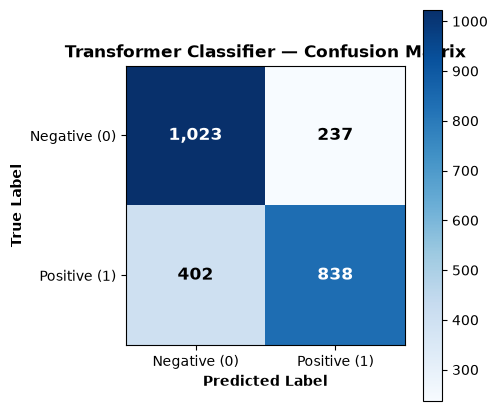

Đã lưu biểu đồ: confusion_matrix.png
Đã lưu bảng kết quả: results.csv


,Model,Representation,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM,Sequential Hidden State,"2,692,481",30.01,0.6124,0.6325,0.5218,0.5718
1,Transformer (4 Heads),Multi-Head Self-Attention + FFN,"2,692,353",121.64,0.7444,0.7795,0.6758,0.7240


In [14]:
# 1. Vẽ ma trận nhầm lẫn (confusion_matrix.png)
trans_preds = (trans_probs >= 0.5).astype(int)
cm = confusion_matrix(y_test_np, trans_preds)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative (0)", "Positive (1)"])
ax.set_yticklabels(["Negative (0)", "Positive (1)"])
ax.set_xlabel("Predicted Label", fontweight="bold")
ax.set_ylabel("True Label", fontweight="bold")
ax.set_title("Transformer Classifier — Confusion Matrix", fontweight="bold")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()
print("Đã lưu biểu đồ: confusion_matrix.png")

# 2. Xuất results.csv theo đúng định dạng Deliverables
results_df = pd.DataFrame([
    {
        "Model": "LSTM",
        "Representation": "Sequential Hidden State",
        "Parameters": f"{lstm_params:,}",
        "Training time (s)": round(lstm_time, 2),
        "Accuracy": round(lstm_acc, 4),
        "Precision": round(lstm_prec, 4),
        "Recall": round(lstm_rec, 4),
        "F1": round(lstm_f1, 4)
    },
    {
        "Model": "Transformer (4 Heads)",
        "Representation": "Multi-Head Self-Attention + FFN",
        "Parameters": f"{trans_params:,}",
        "Training time (s)": round(trans_time, 2),
        "Accuracy": round(trans_acc, 4),
        "Precision": round(trans_prec, 4),
        "Recall": round(trans_rec, 4),
        "F1": round(trans_f1, 4)
    }
])
results_df.to_csv("results.csv", index=False)
print("Đã lưu bảng kết quả: results.csv")
display(results_df)


In [15]:
# Lấy 3 mẫu dự đoán đúng và 3 mẫu dự đoán sai trên tập test
correct_samples = []
incorrect_samples = []

for idx in range(len(y_test_np)):
    true_lbl = int(y_test_np[idx])
    pred_lbl = int(trans_preds[idx])
    prob = float(trans_probs[idx])
    text = df_test["text"].iloc[idx]
    
    if true_lbl == pred_lbl and len(correct_samples) < 3:
        correct_samples.append({
            "idx": idx,
            "true": "pos" if true_lbl == 1 else "neg",
            "pred": "pos" if pred_lbl == 1 else "neg",
            "prob": round(prob, 4),
            "text": text[:200] + "..."
        })
    elif true_lbl != pred_lbl and len(incorrect_samples) < 3:
        incorrect_samples.append({
            "idx": idx,
            "true": "pos" if true_lbl == 1 else "neg",
            "pred": "pos" if pred_lbl == 1 else "neg",
            "prob": round(prob, 4),
            "text": text[:200] + "..."
        })

print("=== 3 MẪU DỰ ĐOÁN ĐÚNG (CORRECT SAMPLES) ===")
for s in correct_samples:
    print(f"Index {s['idx']} | True: {s['true']} | Pred: {s['pred']} (p={s['prob']})\nText: {s['text']}\n")

print("=== 3 MẪU DỰ ĐOÁN SAI (INCORRECT SAMPLES) ===")
for s in incorrect_samples:
    print(f"Index {s['idx']} | True: {s['true']} | Pred: {s['pred']} (p={s['prob']})\nText: {s['text']}\n")


=== 3 MẪU DỰ ĐOÁN ĐÚNG (CORRECT SAMPLES) ===
Index 2 | True: pos | Pred: pos (p=0.8994)
Text: It's nice to see a film with real people with honest feelings. Sissy Spacek is so absolutely convincing as a simple, yet nice, daughter to Robert Farnsworth,<br /><br />who finally, in his last role, ...

Index 3 | True: pos | Pred: pos (p=0.8803)
Text: Buddy is an entertaining family film set in a time when "humanizing" animals, and making them cute was an accepted way to get people to be interested in them.<br /><br />Based on a true story, Buddy s...

Index 4 | True: neg | Pred: neg (p=0.1318)
Text: This movie can't decide what it is -- a soft porno or a sf movie. Not enough plot for a real movie, but way too much for a porno.<br /><br />In a galaxy far far away, a good princess (we know she's go...

=== 3 MẪU DỰ ĐOÁN SAI (INCORRECT SAMPLES) ===
Index 0 | True: pos | Pred: neg (p=0.4504)
Text: This was truly a deeply moving movie in every sense of the word. I myself was a Mormon missionary 